# 22 · Late interaction and MaxSim

## The engineering question
What information is retained by a matrix of learned token vectors, and how does MaxSim combine their matches?

**Learning outcomes:** hand-compute MaxSim; encode real local ColBERT query/document token vectors; verify Qdrant scores against NumPy; compare dense retrieval; measure token-matrix storage and scoring cost.

For normalized query rows qᵢ and document rows dⱼ, MaxSim is Σᵢ maxⱼ(qᵢ·dⱼ). Each query token chooses its best document match; multiple query tokens may choose the same document token. The score is a sum, so query length changes its scale. It is neither a calibrated probability nor a cross-encoder jointly attending over query and document.

Bootstrap once with `uv run vmc bootstrap --model colbert`. We load the pinned 33M-parameter Answer.AI checkpoint locally: learned BERT states projected from 384 to 96 dimensions, explicit query/document marker tokens, 32-position query mask augmentation, up to 300 document positions, and document punctuation masking. The transparent local adapter follows the checkpoint metadata; no CUDA extension or remote Python is executed. Qdrant uses its real multivector MaxSim comparator with graph indexing disabled for this tiny exact example.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("22", "B", docker=True)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


array([[1. , 0.6],
       [0. , 0.8]])

Row maxima: [1.  0.8] sum: 1.8


,query,method,top_source,recall,ndcg
0,d01,ColBERT MaxSim,atlas-warranty@1,1.0,1.00000
1,d01,MiniLM dense,atlas-warranty@1,1.0,1.00000
2,d02,ColBERT MaxSim,atlas-reset@1,1.0,1.00000
3,d02,MiniLM dense,atlas-reset@1,1.0,1.00000
4,d03,ColBERT MaxSim,atlas-error@1,1.0,1.00000
5,d03,MiniLM dense,boreal-error@1,1.0,0.63093
6,d04,ColBERT MaxSim,atlas-firmware@1,1.0,1.00000
7,d04,MiniLM dense,atlas-firmware@1,1.0,1.00000
8,d05,ColBERT MaxSim,atlas-ports@1,1.0,1.00000
9,d05,MiniLM dense,atlas-ports@1,1.0,1.00000


,representation,raw_bytes,stored_rows
0,dense MiniLM,33792,22
1,ColBERT token matrices,309504,806


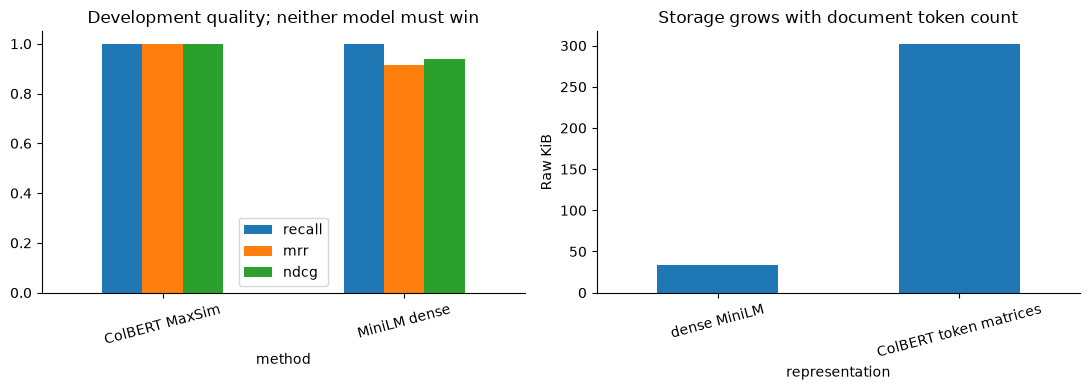

In [2]:
import time
from uuid import uuid4
from qdrant_client import QdrantClient, models as qm
from vector_masterclass.late_interaction import encode_tokens, maxsim
from vector_masterclass.models import embed
from vector_masterclass.data import documents, queries
from vector_masterclass.metrics import ranking_metrics
from vector_masterclass.retrieval import exact_search
from vector_masterclass.config import qdrant_url, model_config, fingerprint

hand_q = np.array([[1.0, 0.0], [0.0, 1.0]])
hand_d = np.array([[1.0, 0.0], [0.6, 0.8]])
hand_matrix = hand_q @ hand_d.T
display(hand_matrix)
print("Row maxima:", hand_matrix.max(axis=1), "sum:", maxsim(hand_q, hand_d))
assert np.isclose(maxsim(hand_q, hand_d), 1.8)
docs = documents(tenant="public")
qs = queries("development")
ids = [d.key for d in docs]
started = time.perf_counter()
document_vectors = encode_tokens([d.text for d in docs])
document_encoding_seconds = time.perf_counter() - started
started = time.perf_counter()
query_vectors = encode_tokens([q.text for q in qs], role="query")
query_encoding_seconds = time.perf_counter() - started
dense = embed([d.text for d in docs])
dense_queries = embed([q.text for q in qs], role="query")
client = QdrantClient(url=qdrant_url(), timeout=30)
name = "vmc_22_" + uuid4().hex[:8]
client.create_collection(
    name,
    vectors_config=qm.VectorParams(
        size=96,
        distance=qm.Distance.COSINE,
        multivector_config=qm.MultiVectorConfig(comparator=qm.MultiVectorComparator.MAX_SIM),
        hnsw_config=qm.HnswConfigDiff(m=0),
    ),
    metadata={"model_signature": fingerprint(model_config("colbert"))},
)
rows = []
maximum_error = 0.0
try:
    client.upsert(
        name,
        points=[
            qm.PointStruct(id=i, vector=v.tolist(), payload={"source": ids[i]})
            for i, v in enumerate(document_vectors)
        ],
        wait=True,
    )
    for q, qv, dq in zip(qs, query_vectors, dense_queries):
        started = time.perf_counter()
        reference = np.array([maxsim(qv, dv) for dv in document_vectors])
        local_seconds = time.perf_counter() - started
        started = time.perf_counter()
        hits = client.query_points(
            name, query=qv.tolist(), limit=len(docs), search_params=qm.SearchParams(exact=True)
        ).points
        server_seconds = time.perf_counter() - started
        maximum_error = float(max(maximum_error, max(abs(h.score - reference[h.id]) for h in hits)))
        ranked = [ids[h.id] for h in hits]
        dense_ranked = [id_ for id_, s in exact_search(dq, dense, ids, k=3)]
        for method, ranking in [("ColBERT MaxSim", ranked), ("MiniLM dense", dense_ranked)]:
            rows.append(
                {
                    "query": q.id,
                    "method": method,
                    "top_source": ranking[0],
                    "server_request_seconds": server_seconds
                    if method == "ColBERT MaxSim"
                    else None,
                    "local_MaxSim_seconds": local_seconds if method == "ColBERT MaxSim" else None,
                    **ranking_metrics(ranking, q.relevance, 3),
                }
            )
finally:
    client.delete_collection(name)
    client.close()
results = lesson.table(pd.DataFrame(rows))
display(results[["query", "method", "top_source", "recall", "ndcg"]])
costs = lesson.table(
    pd.DataFrame(
        [
            {
                "representation": "dense MiniLM",
                "raw_bytes": dense.nbytes,
                "stored_rows": len(dense),
            },
            {
                "representation": "ColBERT token matrices",
                "raw_bytes": sum(v.nbytes for v in document_vectors),
                "stored_rows": sum(len(v) for v in document_vectors),
            },
        ]
    ),
    "costs",
)
display(costs)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
results.groupby("method")[["recall", "mrr", "ndcg"]].mean().plot.bar(ax=axes[0], ylim=(0, 1.05))
axes[0].set(title="Development quality; neither model must win")
axes[0].tick_params(axis="x", rotation=15)
costs.set_index("representation").raw_bytes.div(1024).plot.bar(ax=axes[1])
axes[1].set(ylabel="Raw KiB", title="Storage grows with document token count")
axes[1].tick_params(axis="x", rotation=15)
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Interpretation and exercise
Late interaction pays token-matrix storage and matching cost to preserve local distinctions that pooling can blur. It still truncates long documents and may reward matches without fully modeling negation or relationships. The dense baseline differs in training/model architecture; the comparison is operational, not a controlled attribution of all gains to MaxSim.

**Exercise:** replace sum-of-row-maxima with a global maximum, then compute the hand fixture again. Explain the lost query-coverage signal. Inspect a two-fact query and identify which document rows each query row chooses. Measure candidate recall before using MaxSim as a second-stage scorer.

Training commonly uses contrastive negatives and teacher distillation; hard-negative contamination and teacher errors remain risks. We do not reproduce training or the model author's benchmark scores. The next compression lesson shows why candidate generation and exact rescoring need separate metrics. [Answer.AI model card](https://huggingface.co/answerdotai/answerai-colbert-small-v1), [ColBERT research](https://arxiv.org/abs/2004.12832), [reference tokenization/scoring](https://github.com/stanford-futuredata/ColBERT/tree/main/colbert/modeling).

In [3]:
manifest = lesson.finish(
    {
        "hand_score": bool(np.isclose(maxsim(hand_q, hand_d), 1.8)),
        "actual_token_vectors": all(v.shape[1] == 96 for v in document_vectors),
        "query_augmentation_32": all(v.shape == (32, 96) for v in query_vectors),
        "server_matches_reference": maximum_error < 1e-4,
        "both_baselines_measured": results.method.nunique() == 2,
    },
    observations={
        "max_server_numpy_score_error": maximum_error,
        "document_encoding_seconds": document_encoding_seconds,
        "query_encoding_seconds": query_encoding_seconds,
        "model": model_config("colbert"),
        "split": "development",
        "live_encoding": True,
        "training_reproduction": False,
    },
)

{
  "artifact": "artifacts/20261031T061833Z-009d16/22",
  "checks": {
    "hand_score": true,
    "actual_token_vectors": true,
    "query_augmentation_32": true,
    "server_matches_reference": true,
    "both_baselines_measured": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.